In [1]:
%load_ext autoreload
%autoreload 2

# Fine-tuning on Pre-trained Model for Transcriptomic Enhancement
In this tutorial, we demonstrate how to fine-tune a pre-trained model for transcriptomic enhancement. We use the 10x multiome PBMC dataset which contains both RNA and ATAC measurements.

We summarize the fine-tuning pipeline in the following steps, which can be used as general recipe for fine-tuning on transcriptomic enhancement task and beyond:

    1. Specify hyper-parameter setup for transcriptomic enhancement
    2. Load and pre-process data
    3. Load the pre-trained scPMMI model
    4. fine-tune scPMMI with task-specific objectives
    5. Evaluate fine-tuned scPMMI

In [2]:
import sys
sys.path.append("..")

import warnings
warnings.filterwarnings('ignore')

import os
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import muon as mu
import scanpy as sc
import muon as mu
import random
from tqdm import tqdm
from typing import Tuple
from scipy.sparse import issparse
import swanlab
import matplotlib.pyplot as plt

import torch
from torch import optim, Tensor, nn
from torch.utils.data import DataLoader, Dataset
from torch.amp.autocast_mode import autocast
from transformers.optimization import get_scheduler

from scpmmi.utils.unify import align_to_common_peaks, align_to_common_genes
from scpmmi.tokenizer.vocab import Vocab
from scpmmi.models.scPMMI import scPMMI
from scpmmi.loss import ContrastiveLoss
from scpmmi.utils.util import set_seed
from scpmmi.utils.metrics import (
    biology_conservation, batch_correct
)
from scpmmi import logger

## Step 1: Specify her-parameter setup for enhancement task

In [ ]:
hyperparameter_defaults = dict(
    task='enhancement',
    seed=42,
    dataset_name='10x_multiome_pbmc_10k',
    data_path='../data/mdata/rna_atac/10x_multiome_pbmc_10k.h5mu',
    load_model = '../ckpt/ckpt_epitra',
    gene_vocab='../config_file/default_gene_vocab.json',
    peak_vocab='../config_file/default_peak_vocab.json',
    batch_size=64,
    num_workers=0,
    temperature=0.01,
    alpha=1.5,
    n_epochs=10,
    lr=1e-4,
    weight_decay=0.05,
)

In [4]:
run = swanlab.init(
    project="scPMMI-fine-tuning",
    experiment_name=f"fine-tuning-{time.strftime('%b%d-%H-%M')}",
    config=hyperparameter_defaults,
    reinit=True,
    mode="offline"
)
config = run.config
print(config)
set_seed(config.seed)

swanlab: Tracking run with swanlab version 0.6.8

swanlab: Run data will be saved locally in 
/mnt/disk2/zyuan/code/scPMMI/tutorials/swanlog/run-20260125_202529-nozrrt93pp4stwp9y7opf

swanlab: Backing up run fine-tuning-Jan25-20-25 locally

swanlab:  ☁️ Run `swanlab sync 
/mnt/disk2/zyuan/code/scPMMI/tutorials/swanlog/run-20260125_202529-nozrrt93pp4stwp9y7opf` to sync logs to remote 
server

{'task': 'enhancement', 'seed': 42, 'dataset_name': '10x_multiome_pbmc_10k', 'data_path': '../data/mdata/rna_atac/10x_multiome_pbmc_10k.h5mu', 'load_model': '../result/ablation_mamba_layer_binary/mamba_0_layer_epi_0.3_1/pretraining_epitra_v1_64020_raw/ckpt', 'gene_vocab': '../config_file/default_gene_vocab.json', 'peak_vocab': '../config_file/default_peak_vocab.json', 'batch_size': 64, 'num_workers': 0, 'temperature': 0.01, 'alpha': 1.5, 'n_epochs': 10, 'lr': 0.0001, 'weight_decay': 0.05}


In [5]:
dataset_name = config.dataset_name
save_path = Path(f"./result/save_enhancement/dev_{dataset_name}-{time.strftime('%b%d-%H-%M')}/")
save_path.mkdir(parents=True, exist_ok=True)
print(f"save to {save_path}")

save to result/save_enhancement/dev_10x_multiome_pbmc_10k-Jan25-20-25


## Step 2: Load and pre-process data

### 2.1 load data

In [6]:
if dataset_name == 'multiome_bmmc':
    mdata = mu.read_h5mu(config.data_path)
    adata_rna = mdata.mod['rna']
    adata_atac = mdata.mod['atac'] 
    sc.pp.filter_genes(adata_rna, min_counts=3)
    sc.pp.filter_genes(adata_atac, min_counts=3)
    adata_rna = adata_rna[adata_rna.obs['batch'].isin(['s1d1', 's1d2', 's1d3'])]
    adata_atac = adata_atac[adata_atac.obs['batch'].isin(['s1d1', 's1d2', 's1d3'])]
else:
    mdata = mu.read_h5mu(config.data_path)
    adata_rna = mdata.mod['rna']
    adata_atac = mdata.mod['atac'] 
    sc.pp.filter_genes(adata_rna, min_counts=3)
    sc.pp.filter_genes(adata_atac, min_counts=3)
    
adata_rna, adata_atac

(AnnData object with n_obs × n_vars = 9631 × 25597
     obs: 'cell_type'
     var: 'gene_ids', 'feature_types', 'genome', 'interval', 'n_counts',
 AnnData object with n_obs × n_vars = 9631 × 107257
     obs: 'cell_type'
     var: 'gene_ids', 'feature_types', 'genome', 'interval', 'n_counts')

### 2.2 Match the gene and peak sets to the pre-trained model

In [7]:
gene_vocab = Vocab.from_file(config.gene_vocab)
gene_list = gene_vocab.get_token_list()
gene_ids = gene_vocab(gene_list)
adata_rna = align_to_common_genes(adata_rna, gene_list)    

2026-01-25 20:25:33 - scPMMI - INFO - Number of matched genes: 18282


In [8]:
peak_vocab = Vocab.from_file(config.peak_vocab)
peak_list = peak_vocab.get_token_list()
peak_ids = peak_vocab(peak_list)
adata_atac = align_to_common_peaks(adata_atac, peak_list)

2026-01-25 20:25:46 - scPMMI - INFO - Number of matched peaks: 40885


In [9]:
def downsampling(
    X,
    min_total_count=1000,
    p_gamma=0.5,
    alpha=2,
    beta=2,
    downsample_ratio=None
):
    """
    Vectorized Hierarchical Bayesian down-sampling for batch of cells,
    with an optional fixed downsampling ratio.

    Args:
        X (np.ndarray): Raw gene expression matrix, shape [n_cells, n_genes]
        min_total_count (int): Minimum total count threshold
        p_gamma (float): Probability of gamma=1 in Bernoulli
        alpha, beta (float): Parameters of Beta distribution (used only if downsample_ratio is None)
        downsample_ratio (float or None): Fixed downsampling ratio (0~1).
            If provided, overrides Beta sampling.

    Returns:
        np.ndarray: Down-sampled expression matrix, shape [n_cells, n_genes]
    """
    n_cells, _ = X.shape
    X_downsampled = X.copy()

    # 1. Total counts per cell
    total_counts = X.sum(axis=1)

    # 2. Bernoulli γ for all cells
    gamma = np.random.binomial(1, p_gamma, size=n_cells)

    # 3. Cells eligible for down-sampling
    eligible_mask = (total_counts >= min_total_count)
    eligible_idx = np.where(eligible_mask)[0]

    if eligible_idx.size > 0:
        if downsample_ratio is not None:
            # use fixed downsample rate
            b = np.full(eligible_idx.size, downsample_ratio, dtype=float)
        else:
            # 使用 Beta 分布采样比例
            b = np.random.beta(alpha, beta, size=eligible_idx.size)

        # 4. Binomial down-sampling
        X_downsampled[eligible_idx] = np.random.binomial(X[eligible_idx], b[:, None])

    return X_downsampled


## Step 3: Load the pre-trained scPMMI model

In [10]:
device = 'cuda:2'
torch.cuda.set_device(device)
dtype = torch.bfloat16
model_dir = Path(config.load_model)
model_config_file = model_dir / "config.json"
model_ckpt = model_dir / "model.bin"
with open(model_config_file, "r") as f:
    model_config = json.load(f)
model = scPMMI(model_config, do_mvc=True)

if config.load_model is not None:
    try:
        model.load_state_dict(torch.load(model_ckpt))
        logger.info(f"Loading all model params from {model_ckpt}")
    except:
        # only load params that are in the model and match the size
        model_dict = model.state_dict()
        pretrained_dict = torch.load(model_ckpt)
        pretrained_dict = {
            k: v
            for k, v in pretrained_dict.items()
            if k in model_dict and v.shape == model_dict[k].shape
        }
        for k, v in pretrained_dict.items():
            logger.info(f"Loading params {k} with shape {v.shape}")
        model_dict.update(pretrained_dict)
        model.load_state_dict(model_dict)
model = model.to(device, dtype)

2026-01-25 20:26:45 - scPMMI - INFO - Loading params encoder_mod1.backbone.embedding.cls_token with shape torch.Size([1, 1, 512])
2026-01-25 20:26:45 - scPMMI - INFO - Loading params encoder_mod1.backbone.embedding.patch_position_embeddings with shape torch.Size([1, 160, 512])
2026-01-25 20:26:45 - scPMMI - INFO - Loading params encoder_mod1.backbone.embedding.embedding.weight with shape torch.Size([40957, 512])
2026-01-25 20:26:45 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.norm.weight with shape torch.Size([512])
2026-01-25 20:26:45 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.mixer.Wqkv.weight with shape torch.Size([1536, 512])
2026-01-25 20:26:45 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.mixer.Wqkv.bias with shape torch.Size([1536])
2026-01-25 20:26:45 - scPMMI - INFO - Loading params encoder_mod1.backbone.layers.0.mixer.out_proj.weight with shape torch.Size([512, 512])
2026-01-25 20:26:45 - scPMMI - INFO - Loading params

In [11]:
class MultiSeqDataset(Dataset):
    def __init__(
        self,
        adata_mod1: sc.AnnData,
        feature_ids_mod1: list,
        adata_mod2: sc.AnnData,
        feature_ids_mod2: list,
        dtype=torch.float32
    ):
        """
        PyTorch-compatible dataset for paired multi-modal single-cell sequencing data.

        Args:
            adata_mod1: AnnData object for the first modality (e.g., RNA).
            layer_mod1: Layer name in adata_mod1 to use as input.
            adata_mod2: AnnData object for the second modality (e.g., ATAC).
            layer_mod2: Layer name in adata_mod2 to use as input.
        """
        self.feature_ids_mod1 = torch.tensor(feature_ids_mod1, dtype=torch.int32)
        self.feature_ids_mod2 = torch.tensor(feature_ids_mod2, dtype=torch.int32)
        # ---------------------- Process first modality ----------------------
        X_rna = adata_mod1.X.toarray() if issparse(adata_mod1.X) else adata_mod1.X # type: ignore
        X_rna = X_rna.astype(np.int32, casting="unsafe") # type: ignore
        X_rna = downsampling(X_rna, min_total_count=1000, downsample_ratio=0.1)
        X_rna_input = torch.tensor(X_rna, dtype=dtype)
        X_rna_input = torch.log1p(X_rna_input / X_rna_input.sum(1)[:, None] * 1e4)
        tokens_gene = self.feature_ids_mod1.unsqueeze(0).repeat(X_rna_input.size(0), 1)

        # ---------------------- Process second modality ----------------------
        X_atac = adata_mod2.X.toarray() if issparse(adata_mod2.X) else adata_mod2.X # type: ignore

        X_atac_input = torch.tensor(X_atac, dtype=dtype)
        X_atac_input = (X_atac_input > 0).float()

        tokens_peak = self.feature_ids_mod2.unsqueeze(0).repeat(X_atac_input.size(0), 1)
        
        # ---------------------- Store both modalities ----------------------
        self.data = {
            "mod1_token_ids": tokens_gene,
            "mod1_values": X_rna_input,
            "mod1_values_target": X_rna_input,

            "mod2_token_ids": tokens_peak,
            "mod2_values": X_atac_input,
            "mod2_values_target": X_atac_input,
        }

    def __len__(self):
        return self.data["mod1_token_ids"].shape[0]

    def __getitem__(self, idx):
        return {k: v[idx] for k, v in self.data.items()}

In [12]:
dataset = MultiSeqDataset(adata_mod1=adata_rna, feature_ids_mod1=gene_ids, 
                            adata_mod2=adata_atac, feature_ids_mod2=peak_ids)

data_loader = DataLoader(dataset, batch_size=config.batch_size, shuffle=False,
                    num_workers=config.num_workers, pin_memory=True)

In [13]:
criterion_clip = ContrastiveLoss(
    temperature=config.temperature, alpha=config.alpha
)
criterion_bce = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW( # type: ignore
    model.parameters(), lr=config.lr, weight_decay=config.weight_decay
)
max_train_steps = config.n_epochs * len(data_loader)
num_warmup_steps = int(0.1 * max_train_steps)  # 10% steps for warmup
scheduler = get_scheduler(
    name="cosine",
    optimizer=optimizer,
    num_warmup_steps=num_warmup_steps,
    num_training_steps=max_train_steps,
)

In [14]:
model.train()
global_step = 0
for epoch in range(config.n_epochs):
    loop = tqdm(data_loader, desc=f'Epoch [{epoch}/{config.n_epochs}]',leave=False)
    for step, batch_data in enumerate(loop):
        mod1_token_ids = batch_data["mod1_token_ids"].to(device)
        mod1_values_input = batch_data["mod1_values"].to(device)

        mod2_token_ids = batch_data["mod2_token_ids"].to(device)
        mod2_values_input = batch_data["mod2_values"].to(device)
        mod2_values_target = batch_data["mod2_values_target"].to(device)


        optimizer.zero_grad()
        with autocast(device_type="cuda", dtype=dtype):
            output = model(
                mod1_token_ids, mod1_values_input, 
                mod2_token_ids, mod2_values_input,
                MVC=True,
            )
            metric_to_log = {}
            loss_clip = criterion_clip(output['cell_emb_mod1'], output['cell_emb_mod2'])
            loss = loss_clip
            metric_to_log['clip'] = loss_clip.item()

            loss_bce = criterion_bce(output['mvc_output_mod2'], mod2_values_target.to(output['mvc_output_mod2']))
            loss += loss_bce
            metric_to_log['mvc_bce'] = loss_bce.item()
        
        metric_to_log['loss'] = loss.item()
        metric_to_log['step'] = global_step
        metric_to_log['lr'] = scheduler.get_last_lr()[0]
        loss.backward()
        optimizer.step()
        scheduler.step()
        global_step += 1
        loop.set_postfix(metric_to_log)
                    
        swanlab.log(metric_to_log)


Epoch [0/10]:   0%|          | 0/151 [00:00<?, ?it/s]

In [15]:
model.save_pretrained(save_path / 'ckpt')

## Step 5: Inference and Evaluation

In [16]:
model.eval()        
test_loader = DataLoader(dataset, batch_size=config.batch_size, shuffle=False,
                        num_workers=config.num_workers, pin_memory=True)
with torch.no_grad():
    cell_emb_rna, cell_emb_atac = [], []
    for batch_data in tqdm(test_loader, desc="Inference"):
        mod1_token_ids = batch_data["mod1_token_ids"].to(device)
        mod1_values_input = batch_data["mod1_values"].to(device)
        mod1_values_target = batch_data["mod1_values_target"].to(device)

        mod2_token_ids = batch_data["mod2_token_ids"].to(device)
        mod2_values_input = batch_data["mod2_values"].to(device)
        mod2_values_target = batch_data["mod2_values_target"].to(device)
        
        output = model(mod1_token_ids, mod1_values_input, mod2_token_ids, mod2_values_input)
        cell_emb_rna.append(output['cell_emb_mod1'].cpu())
        cell_emb_atac.append(output['cell_emb_mod2'].cpu())

    cell_emb_rna = torch.cat(cell_emb_rna, dim=0).to(torch.float32).numpy()
    cell_emb_atac = torch.cat(cell_emb_atac, dim=0).to(torch.float32).numpy()

    adata_rna.obs['modality'] = 'rna'
    adata_atac.obs['modality'] = 'atac'
    X = np.concatenate((cell_emb_rna, cell_emb_atac), axis=0)
    obs = pd.concat([adata_rna.obs, adata_atac.obs], ignore_index=True)
    concat_cell_emb = sc.AnnData(X=X, obs=obs)

Inference:   0%|          | 0/151 [00:00<?, ?it/s]

Inference: 100%|██████████| 151/151 [00:17<00:00,  8.51it/s]


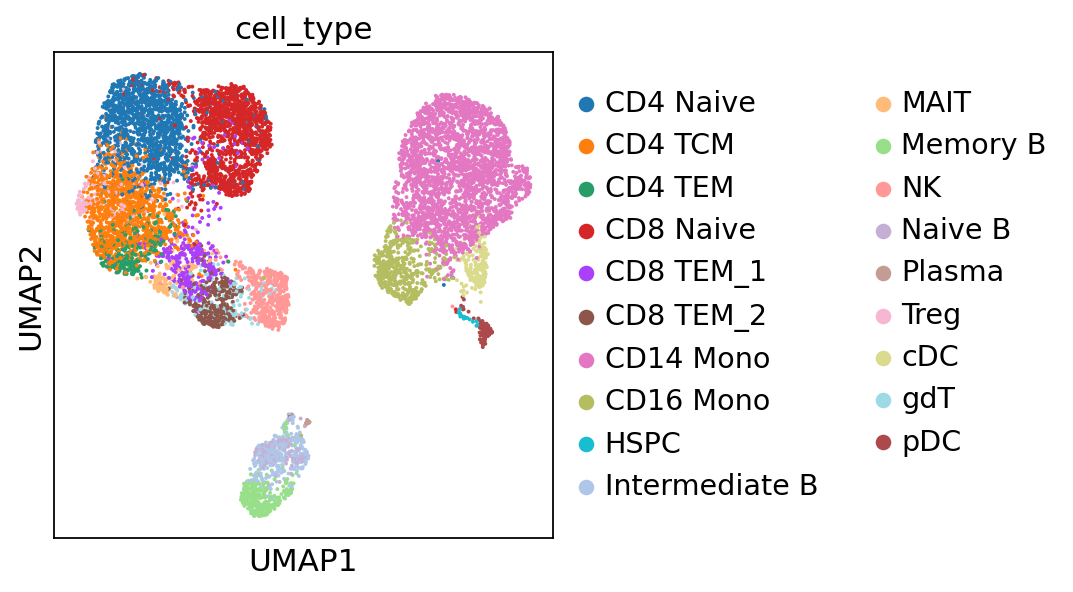

In [17]:
sc.set_figure_params(figsize=(4, 4))
cell_emb_rna = concat_cell_emb[concat_cell_emb.obs['modality'] == 'rna'].X
cell_emb_atac = concat_cell_emb[concat_cell_emb.obs['modality'] == 'atac'].X
emb = (cell_emb_atac + cell_emb_rna)
obs = concat_cell_emb[concat_cell_emb.obs['modality'] == 'rna'].obs
EmbAdata = sc.AnnData(X=emb, obs=obs)

sc.pp.neighbors(EmbAdata, metric="cosine", n_neighbors=30)
sc.tl.umap(EmbAdata, min_dist=0.5, spread=1.0)
sc.pl.umap(EmbAdata, color=['cell_type'], ncols=2, wspace=0.3)
EmbAdata.write(save_path / "cell_emb.h5ad")

In [18]:
metrics = {}
logger.info("Calculating biology conservation metrics...")
biology_conservation_metrics, best_res= biology_conservation(
    EmbAdata, EmbAdata.obs['cell_type'].values, start=20, end=40, scale=100,
)
metrics['BioCons'] = round(float(np.mean(list(biology_conservation_metrics.values()))), 3)
biology_conservation_metrics = {k: round(float(v), 3) for k, v in biology_conservation_metrics.items()}
metrics.update(biology_conservation_metrics)
metrics

2026-01-25 20:34:00 - scPMMI - INFO - Calculating biology conservation metrics...


{'BioCons': 0.763,
 'ARI': 0.8,
 'NMI': 0.799,
 'Mean average precision': 0.841,
 'ASW_celltype': 0.612}

In [19]:
if not os.path.exists(f'{save_path}/metrics.csv'):
    metrics_df = pd.DataFrame([metrics])
else:
    metrics_df = pd.read_csv(
        f'{save_path}/metrics.csv' 
    )
    new_metrics_df = pd.DataFrame([metrics])
    metrics_df = pd.concat([metrics_df, new_metrics_df], ignore_index=True)
metrics_df.to_csv(f'{save_path}/metrics.csv', index=False)